# EDA: датасет отеля

Разбор `data/hotels/dataset.json` — оценочных пар «вопрос клиента / ответ».

Проверяю три вещи:

- объём: сколько пар, как они делятся на справочные и вопросы о заезде, насколько длинные тексты;
- качество полей: пустые значения, схема, повтор вопроса с разными ответами;
- пригодность для RAG: содержит ли вопрос однозначное имя карточки, и совпадает ли ответ о заезде с таблицей доступности.


In [1]:
import json
import re
from collections import Counter, defaultdict
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "font.size": 11,
    }
)

KIND_COLOR = {"knowledge": "#1f4e5f", "availability": "#c47b4a"}
KIND_LABEL = {"knowledge": "справочные", "availability": "заезд"}


def project_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Не найден корень проекта.")


ROOT = project_root()
HOTELS = ROOT / "data" / "hotels"
rows = json.loads((HOTELS / "dataset.json").read_text(encoding="utf-8"))
calendar = json.loads((HOTELS / "availability.json").read_text(encoding="utf-8"))
cards = []
for filename in ("rooms.json", "special.json", "contacts.json"):
    cards.extend(json.loads((HOTELS / filename).read_text(encoding="utf-8")))

knowledge = [row for row in rows if row["kind"] == "knowledge"]
availability = [row for row in rows if row["kind"] == "availability"]
print(f"записей: {len(rows)}")
print(f"справочные: {len(knowledge)}")
print(f"заезд: {len(availability)}")
print(f"карточек каталога: {len(cards)}")
print(f"таблиц доступности: {len(calendar)}")

записей: 128
справочные: 72
заезд: 56
карточек каталога: 24
таблиц доступности: 14


## Объём

Справочные вопросы должны покрывать карточки каталога, вопросы о заезде — номера и длительность проживания.


In [2]:
MONTHS = {
    name: index
    for index, name in enumerate(
        (
            "января",
            "февраля",
            "марта",
            "апреля",
            "мая",
            "июня",
            "июля",
            "августа",
            "сентября",
            "октября",
            "ноября",
            "декабря",
        ),
        start=1,
    )
}
DATE_RE = re.compile(r"(\d{1,2}) (" + "|".join(MONTHS) + r") (\d{4}) года")
NIGHTS_RE = re.compile(r"на (\d+) ноч")
room_names = sorted(
    (card["name"] for card in json.loads((HOTELS / "rooms.json").read_text(encoding="utf-8"))),
    key=len,
    reverse=True,
)


def stay_span(question: str) -> tuple[str, int]:
    room = next(name for name in room_names if name.casefold() in question.casefold())
    found = [
        date(int(year), MONTHS[month], int(day)) for day, month, year in DATE_RE.findall(question)
    ]
    if question.startswith("Можно ли забронировать"):
        check_in, check_out = found
    else:
        check_in = found[0]
        check_out = check_in + timedelta(days=int(NIGHTS_RE.search(question).group(1)))
    return room, (check_out - check_in).days


def lengths(items, field):
    return [len(item[field]) for item in items]

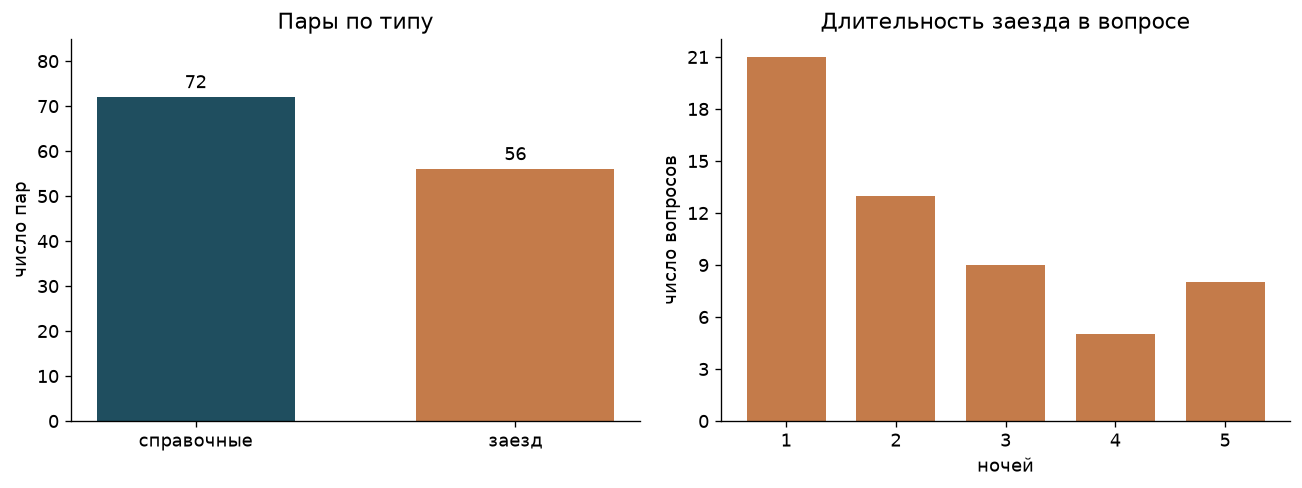

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

nights = Counter(stay_span(row["question"])[1] for row in availability)
kind_counts = Counter(row["kind"] for row in rows)
labels = [KIND_LABEL[kind] for kind in ("knowledge", "availability")]
values = [kind_counts[kind] for kind in ("knowledge", "availability")]
colors = [KIND_COLOR[kind] for kind in ("knowledge", "availability")]
bars = axes[0].bar(labels, values, color=colors, width=0.62)
axes[0].set_title("Пары по типу")
axes[0].set_ylabel("число пар")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, values, strict=True):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 1, str(value), ha="center", va="bottom")
axes[0].set_ylim(0, max(values) * 1.18)

axes[1].bar(
    [str(night) for night in range(1, 6)],
    [nights[night] for night in range(1, 6)],
    color=KIND_COLOR["availability"],
    width=0.72,
)
axes[1].set_title("Длительность заезда в вопросе")
axes[1].set_xlabel("ночей")
axes[1].set_ylabel("число вопросов")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()
plt.show()

## Качество

Справочный вопрос считаю однозначным, если в нём находится отличительное имя ровно одной карточки.
Для номера это текст в последних «ёлочках» названия, для акции и контактов — название целиком.
Совпадение по вхождению: «ПРЕМЬЕР» находится и внутри «ГРАНД ПРЕМЬЕР», «FOUR SEASONS» — внутри «FOUR SEASONS EXECUTIVE».

Ответ о заезде сверяю с `availability.json`: «Да» только если свободна каждая ночь от заезда до выезда, не включая день выезда.


In [4]:
required = {"kind", "question", "answer"}
unknown_keys = [sorted(row) for row in rows if set(row) != required]
empty = [
    index
    for index, row in enumerate(rows)
    if not str(row.get("question", "")).strip() or not str(row.get("answer", "")).strip()
]
unknown_kinds = sorted({row["kind"] for row in rows} - set(KIND_LABEL))
bad_stay_answers = [row["answer"] for row in availability if row["answer"] not in {"Да", "Нет"}]

by_question = defaultdict(list)
for row in rows:
    by_question[row["question"]].append(row)
conflicts = {
    question: items
    for question, items in by_question.items()
    if len({item["answer"] for item in items}) > 1
}

slots_by_room = {
    item["subject"]: {date.fromisoformat(slot["date"]): slot["available"] for slot in item["slots"]}
    for item in calendar
}
calendar_mismatch = []
calendar_unparsed = []
for row in availability:
    try:
        room, _nights = stay_span(row["question"])
        found = [
            date(int(year), MONTHS[month], int(day))
            for day, month, year in DATE_RE.findall(row["question"])
        ]
        if row["question"].startswith("Можно ли забронировать"):
            check_in, check_out = found
        else:
            check_in = found[0]
            check_out = check_in + timedelta(days=_nights)
        day = check_in
        nights_open = []
        while day < check_out:
            nights_open.append(slots_by_room[room][day])
            day += timedelta(days=1)
    except (KeyError, StopIteration, IndexError, AttributeError):
        calendar_unparsed.append(row["question"])
        continue
    expected = "Да" if nights_open and all(nights_open) else "Нет"
    if expected != row["answer"]:
        calendar_mismatch.append((row["question"], row["answer"], expected))


def distinctive_name(name: str) -> str:
    quoted = re.findall(r"«([^»]+)»", name)
    return quoted[-1] if quoted else name


def matching_cards(question: str) -> list[str]:
    text = question.casefold()
    return [card["name"] for card in cards if distinctive_name(card["name"]).casefold() in text]


match_counts = Counter(len(matching_cards(row["question"])) for row in knowledge)
ambiguous = [row for row in knowledge if len(matching_cards(row["question"])) != 1]
missing_cards = [
    card["name"]
    for card in cards
    if not any(
        distinctive_name(card["name"]).casefold() in row["question"].casefold() for row in knowledge
    )
]
contact_markers = ("ФорСи", "277-71-00", "Охотный ряд")
contacts_mentioned = [
    marker
    for marker in contact_markers
    if any(marker.casefold() in f"{row['question']} {row['answer']}".casefold() for row in rows)
]

print(f"""схема не {{kind, question, answer}}: {len(unknown_keys)}
пустые вопрос или ответ: {len(empty)}
неизвестные kind: {unknown_kinds or "нет"}
""")

print(f"повтор вопроса с разными ответами: {len(conflicts)}")
for question, items in conflicts.items():
    print(f"  {question}")
    for item in items:
        print(f"    [{item['kind']}] {item['answer']}")

print(f"""
ответы о заезде вне «Да»/«Нет»: {len(bad_stay_answers)}
ответы о заезде расходятся с таблицей: {len(calendar_mismatch)}
вопросы о заезде не разобраны: {len(calendar_unparsed)}
""")

print("справочные вопросы по числу подходящих карточек:")
for count in sorted(match_counts):
    print(f"  {count}: {match_counts[count]}")
print(f"однозначные справочные: {match_counts[1]} из {len(knowledge)}\n")

print("карточки, чьё имя не встречается ни в одном справочном вопросе:")
for name in missing_cards:
    print(f"  {name}")

схема не {kind, question, answer}: 0
пустые вопрос или ответ: 0
неизвестные kind: нет

повтор вопроса с разными ответами: 2
  Сколько человек может разместиться в номере ПРЕМЬЕР?
    [knowledge] Вместимость номера категории ПРЕМЬЕР — 3 взрослых или 2 взрослых с ребенком.
    [knowledge] Номер ПРЕМЬЕР вмещает 4 взрослых или 2 взрослых с 2 детьми.
  Какая площадь у люксов FOUR SEASONS EXECUTIVE?
    [knowledge] Площадь люксов составляет от 125 до 136 кв.м.
    [knowledge] Площадь составляет от 81 до 97 кв.м.

ответы о заезде вне «Да»/«Нет»: 0
ответы о заезде расходятся с таблицей: 0
вопросы о заезде не разобраны: 0

справочные вопросы по числу подходящих карточек:
  0: 15
  1: 28
  2: 14
  3: 6
  5: 9
однозначные справочные: 28 из 72

карточки, чьё имя не встречается ни в одном справочном вопросе:
  Откройте для себя Москву
  Больше впечатлений с депозитом на дополнительные расходы
  Продлите впечатления в отеле – третья ночь в подарок
  Оставайтесь с нами дольше – четвертая ночь в подар

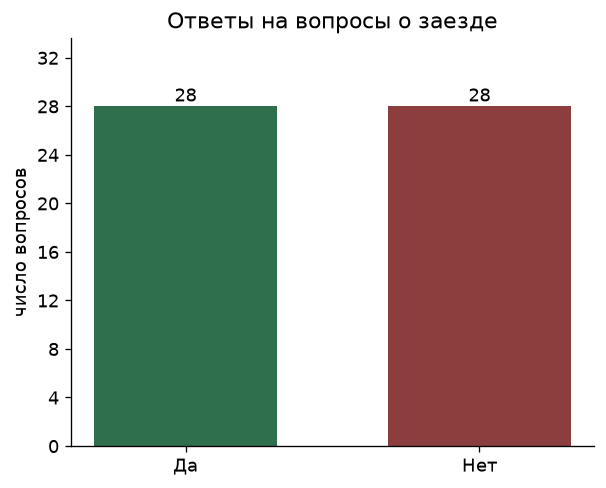

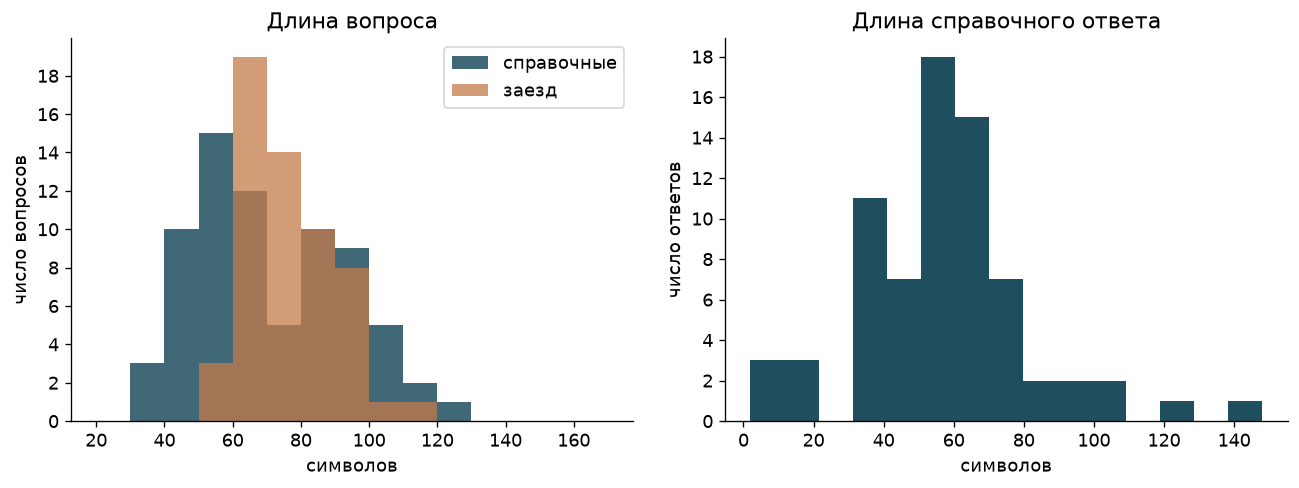

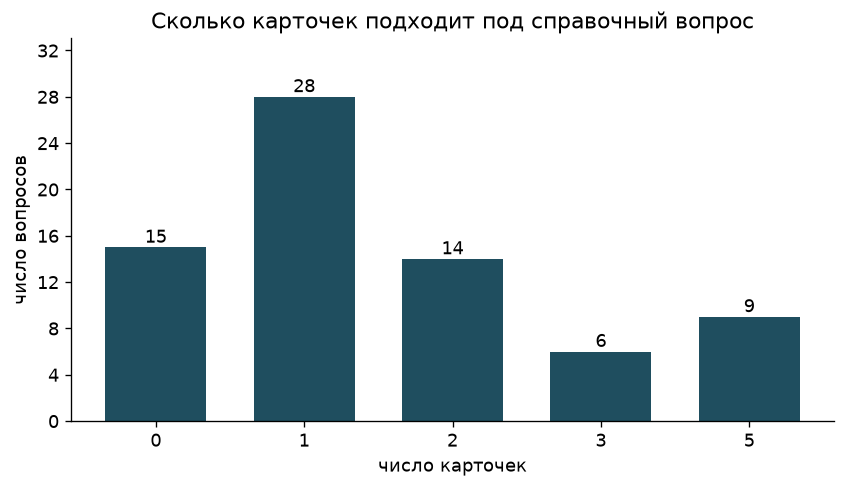

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))

answer_counts = Counter(row["answer"] for row in availability)
answer_labels = ["Да", "Нет"]
answer_values = [answer_counts[label] for label in answer_labels]
bars = ax.bar(answer_labels, answer_values, color=["#2f6f4e", "#8c3d3d"], width=0.62)
ax.set_title("Ответы на вопросы о заезде")
ax.set_ylabel("число вопросов")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, answer_values, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, str(value), ha="center")
ax.set_ylim(0, max(answer_values) * 1.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(20, 180, 10)
axes[0].hist(
    lengths(knowledge, "question"),
    bins=bins,
    color=KIND_COLOR["knowledge"],
    alpha=0.85,
    label="справочные",
)
axes[0].hist(
    lengths(availability, "question"),
    bins=bins,
    color=KIND_COLOR["availability"],
    alpha=0.75,
    label="заезд",
)
axes[0].set_title("Длина вопроса")
axes[0].set_xlabel("символов")
axes[0].set_ylabel("число вопросов")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

axes[1].hist(lengths(knowledge, "answer"), bins=15, color=KIND_COLOR["knowledge"])
axes[1].set_title("Длина справочного ответа")
axes[1].set_xlabel("символов")
axes[1].set_ylabel("число ответов")
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2))
match_order = sorted(match_counts)
match_values = [match_counts[count] for count in match_order]
bars = ax.bar(
    [str(count) for count in match_order], match_values, color=KIND_COLOR["knowledge"], width=0.68
)
ax.set_title("Сколько карточек подходит под справочный вопрос")
ax.set_xlabel("число карточек")
ax.set_ylabel("число вопросов")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
for bar, value in zip(bars, match_values, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, str(value), ha="center")
ax.set_ylim(0, max(match_values) * 1.18)
fig.tight_layout()
plt.show()

## Что из этого следует

Вопросы о заезде собраны ровно: у каждого из 14 номеров четыре вопроса, «Да» и «Нет» по 28, и все 56 ответов совпадают с календарём свободных ночей.

Справочная часть для замера ответов на основе RAG слабее. Из 72 вопросов однозначное имя карточки есть у 28. У 29 вопрос цепляет две, три или пять карточек (к примеру, в тексте остаётся общий фрагмент «ПРЕМЬЕР», «ДЕЛЮКС» или «FOUR SEASONS»). Вполне ожидаемая реалистичная ситуация, для retriever части буду рассматривать top_k 3-5. Ещё 15 вопросов не содержат отличительного имени (якоря к документу) вообще.

Два вопроса записаны дважды и с разными ответами. Про вместимость номера ПРЕМЬЕР один ответ даёт «3 взрослых или 2 взрослых с ребенком», другой — «4 взрослых или 2 взрослых с 2 детьми». Про площадь люксов FOUR SEASONS EXECUTIVE один ответ даёт 125–136 кв.м., другой — 81–97 кв.м. В процессе EDA изучил эти аномалии: речь идет о разных номерах с одинаковым названием, но с разными видами из окон.
